# Perbandingan KNN: Euclidean vs Manhattan vs Cosine vs Minkowski
Membandingkan empat metrik jarak pada KNN (K=5, `weights='uniform'`; Minkowski memakai `p=3`) untuk klasifikasi `Burnout_Risk`
berdasarkan:

1. **Accuracy**
2. **Precision**
3. **Recall**
4. **F1-Score**
5. **Confusion Matrix**

Notebook ini **mandiri**: data dimuat, diproses, dan keempat model dilatih langsung di sini dengan preprocessing,
pembagian data (80:20, stratified, `random_state=42`), dan pengaturan model yang sama dengan empat notebook KNN


## 0. Setup

In [3]:
import os
import time
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputPerbandinganKNN'
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_NAMES = ['Low (0)', 'Moderate (1)', 'High (2)']
LABELS = [0, 1, 2]
METRICS = ['Euclidean', 'Manhattan', 'Cosine', 'Minkowski']
COLORS = {'Euclidean': '#2b5c8f', 'Manhattan': '#e67e22', 'Cosine': '#27ae60', 'Minkowski': '#8e44ad'}
MINKOWSKI_P = 3  # p=1 sama dengan Manhattan dan p=2 sama dengan Euclidean, jadi dipakai p=3


def make_knn(name):
    if name == 'Minkowski':
        return KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=MINKOWSKI_P, weights='uniform')
    return KNeighborsClassifier(n_neighbors=5, metric=name.lower(), weights='uniform')

## 1. Data dan Preprocessing

Tahapan sama dengan notebook KNN sebelumnya: sampling 5.000 data, seleksi kolom, encoding ordinal, lalu pembagian data latih/uji. Imputasi rata-rata dan standardisasi di-fit hanya pada data latih.

In [4]:
DATA_PATH = 'burnout_dataset1.csv'
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print('Silakan upload file burnout_dataset1.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f'{DATA_PATH} tidak ditemukan.'
        )

df = pd.read_csv(DATA_PATH)
print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


In [5]:
numeric_columns = df.select_dtypes(include='number').columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

print('Kolom Numerik:')
print(numeric_columns.tolist())

print('\nKolom Kategorikal:')
print(categorical_columns.tolist())


y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = list(numeric_columns) + list(categorical_columns)

X = df[selected_columns].copy()

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


In [6]:
encoding_maps = {
    'Remote_Work': {'No': 0, 'Hybrid': 1, 'Yes': 2},
    'Sleep_Quality': {'Excellent': 0, 'Good': 1, 'Average': 2, 'Poor': 3},
    'Stress_Level': {'Low': 0, 'Moderate': 1, 'High': 2},
    'Exercise_Frequency': {'Daily': 0, 'Weekly': 1, 'Rarely': 2, 'Never': 3},
    'Alcohol_Consumption': {'No': 0, 'Yes': 1},
    'Smoking': {'No': 0, 'Yes': 1},
    'Healthy_Diet': {'No': 1, 'Yes': 0},
    'Chronic_Stress': {'No': 0, 'Yes': 1},
    'Family_History_Mental_Illness': {'No': 0, 'Yes': 1},
    'Therapy_Attendance': {'No': 1, 'Yes': 0},
    'Support_System': {'Poor': 3, 'Average': 2, 'Good': 1, 'Excellent': 0},
    'Mental_Health_Status': {'Healthy': 0, 'Needs Attention': 1, 'Critical': 2}
}

for column, mapping in encoding_maps.items():
    X[column] = X[column].map(mapping)

target_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
y = y.map(target_mapping)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Dimensi X_train:', X_train.shape)
print('Dimensi X_test :', X_test.shape)


# Imputasi (rata-rata) dan standardisasi HANYA di-fit pada data latih,
# lalu diterapkan ke data uji agar tidak ada kebocoran informasi (data leakage).
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()

X_train_s = pd.DataFrame(
    scaler.fit_transform(imputer.fit_transform(X_train)),
    columns=X.columns,
    index=X_train.index
)

X_test_s = pd.DataFrame(
    scaler.transform(imputer.transform(X_test)),
    columns=X.columns,
    index=X_test.index
)


print('Distribusi kelas data uji:')
print(y_test.value_counts().sort_index())

Dimensi X_train: (4000, 31)
Dimensi X_test : (1000, 31)
Distribusi kelas data uji:
Burnout_Risk
0    496
1    303
2    201
Name: count, dtype: int64


## 2. Melatih Keempat Model KNN

Hanya metrik jarak yang berbeda; K=5 dan `weights='uniform'` sama untuk semuanya.

In [8]:
models = {name: make_knn(name) for name in METRICS}

y_preds = {}
runtime_rows = []

for name, model in models.items():
    t0 = time.process_time()
    model.fit(X_train_s, y_train)
    fit_t = time.process_time() - t0

    t0 = time.process_time()
    y_preds[name] = model.predict(X_test_s)
    pred_t = time.process_time() - t0

    runtime_rows.append({
        'Metrik Jarak': name,
        'Waktu Fit (s)': round(fit_t, 4),
        'Waktu Prediksi (s)': round(pred_t, 4)
    })

print('Keempat model selesai dilatih dan memprediksi data uji.')

Keempat model selesai dilatih dan memprediksi data uji.


## 3. Perbandingan Accuracy, Precision, Recall, dan F1-Score

Karena target memiliki 3 kelas, precision/recall/F1 perlu dirata-ratakan:

- **Macro**: rata-rata sederhana antar kelas, setiap kelas berbobot sama (lebih sensitif terhadap kelas minoritas).
- **Weighted**: rata-rata dibobot jumlah sampel tiap kelas.

### 3.1 Tabel metrik keseluruhan (data uji)

In [9]:
rows = []
for name in METRICS:
    yp = y_preds[name]
    rows.append({
        'Metrik Jarak': name,
        'Accuracy': accuracy_score(y_test, yp),
        'Precision (Macro)': precision_score(y_test, yp, average='macro'),
        'Recall (Macro)': recall_score(y_test, yp, average='macro'),
        'F1 (Macro)': f1_score(y_test, yp, average='macro'),
        'Precision (Weighted)': precision_score(y_test, yp, average='weighted'),
        'Recall (Weighted)': recall_score(y_test, yp, average='weighted'),
        'F1 (Weighted)': f1_score(y_test, yp, average='weighted'),
    })

df_overall = pd.DataFrame(rows).set_index('Metrik Jarak')

# Sorot nilai terbaik pada tiap kolom
df_overall.round(4).style.highlight_max(axis=0, color='#c8e6c9')

,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Precision (Weighted),Recall (Weighted),F1 (Weighted)
Metrik Jarak,,,,,,,
Euclidean,0.839000,0.830700,0.805100,0.815000,0.841900,0.839000,0.838500
Manhattan,0.898000,0.887100,0.878100,0.882000,0.899000,0.898000,0.898100
Cosine,0.835000,0.812300,0.817500,0.810500,0.832600,0.835000,0.830100
Minkowski,0.808000,0.800900,0.771000,0.782500,0.811000,0.808000,0.807200


### 3.2 Diagram batang perbandingan metrik keseluruhan

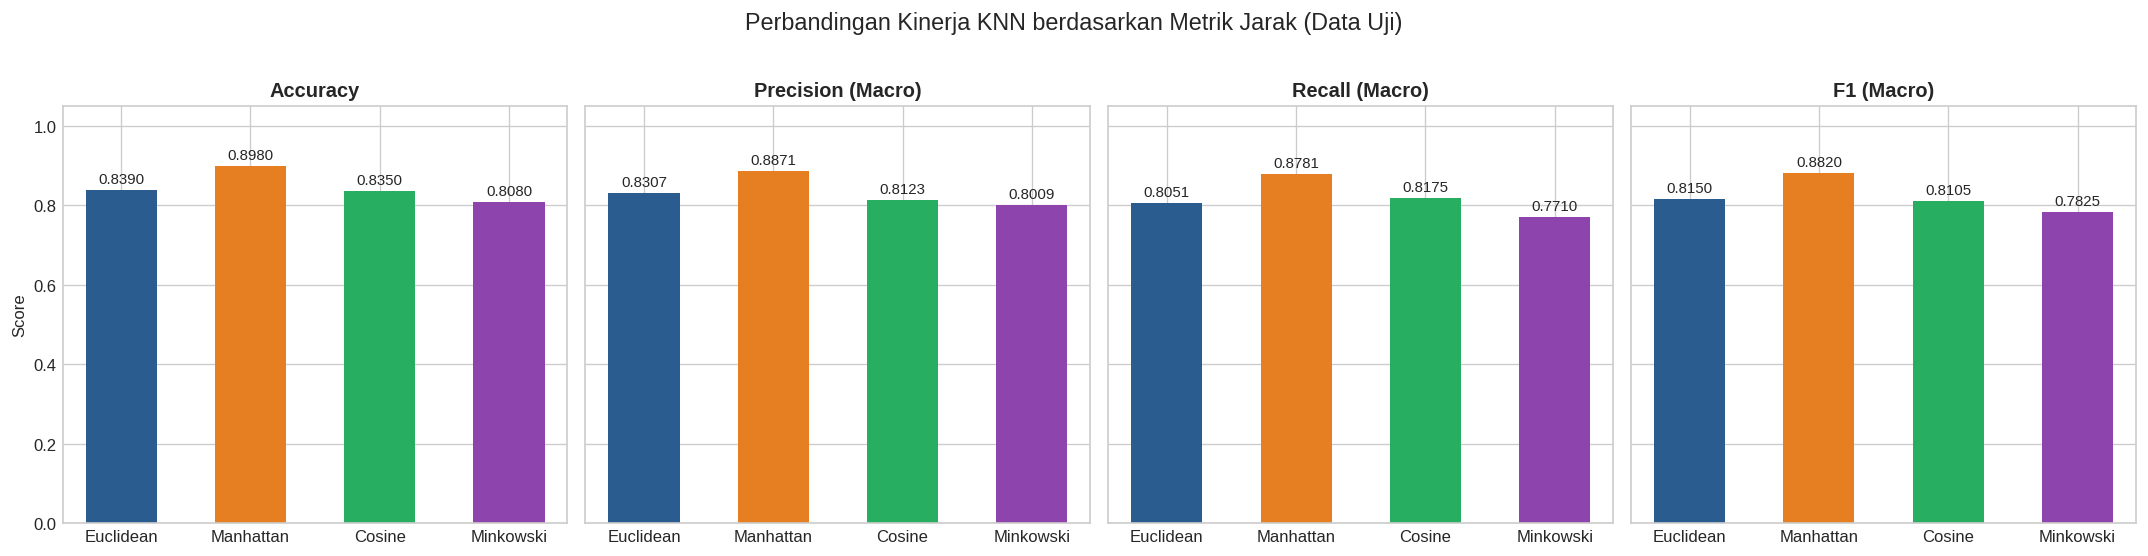

In [10]:
plot_cols = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1 (Macro)']

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)

for ax, col in zip(axes, plot_cols):
    vals = df_overall[col]
    bars = ax.bar(vals.index, vals.values, color=[COLORS[m] for m in vals.index], width=0.55)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1.05)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
                f'{b.get_height():.4f}', ha='center', va='bottom', fontsize=9)

axes[0].set_ylabel('Score')
plt.suptitle('Perbandingan Kinerja KNN berdasarkan Metrik Jarak (Data Uji)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/perbandingan_metrik_keseluruhan.png', bbox_inches='tight')
plt.show()

### 3.3 Metrik per kelas (Precision, Recall, F1-Score)

Rata-rata keseluruhan bisa menyembunyikan perbedaan antar kelas, jadi metrik dihitung juga per kelas.

In [11]:
per_class_rows = []
for name in METRICS:
    p, r, f, s = precision_recall_fscore_support(
        y_test, y_preds[name], labels=LABELS, zero_division=0
    )
    for i, cls in enumerate(TARGET_NAMES):
        per_class_rows.append({
            'Metrik Jarak': name,
            'Kelas': cls,
            'Precision': p[i],
            'Recall': r[i],
            'F1-Score': f[i],
            'Support': int(s[i])
        })

df_per_class = pd.DataFrame(per_class_rows)

# Tabel lebar: baris = kelas, kolom = (metrik evaluasi, metrik jarak)
df_per_class_wide = df_per_class.pivot(
    index='Kelas', columns='Metrik Jarak', values=['Precision', 'Recall', 'F1-Score']
).reindex(TARGET_NAMES)
df_per_class_wide = df_per_class_wide[
    [(m, d) for m in ['Precision', 'Recall', 'F1-Score'] for d in METRICS]
]

df_per_class_wide.round(4)

Precision                                Recall            \
Metrik Jarak Euclidean Manhattan  Cosine Minkowski Euclidean Manhattan   
Kelas                                                                    
Low (0)         0.9077    0.9517  0.8912    0.8798    0.9315    0.9536   
Moderate (1)    0.7178    0.8170  0.7828    0.6718    0.7723    0.8548   
High (2)        0.8667    0.8925  0.7629    0.8509    0.7114    0.8259   

                                F1-Score                              
Metrik Jarak  Cosine Minkowski Euclidean Manhattan  Cosine Minkowski  
Kelas                                                                 
Low (0)       0.9415    0.9153    0.9194    0.9527  0.9157    0.8972  
Moderate (1)  0.6304    0.7162    0.7440    0.8355  0.6984    0.6933  
High (2)      0.8806    0.6816    0.7814    0.8579  0.8176    0.7569

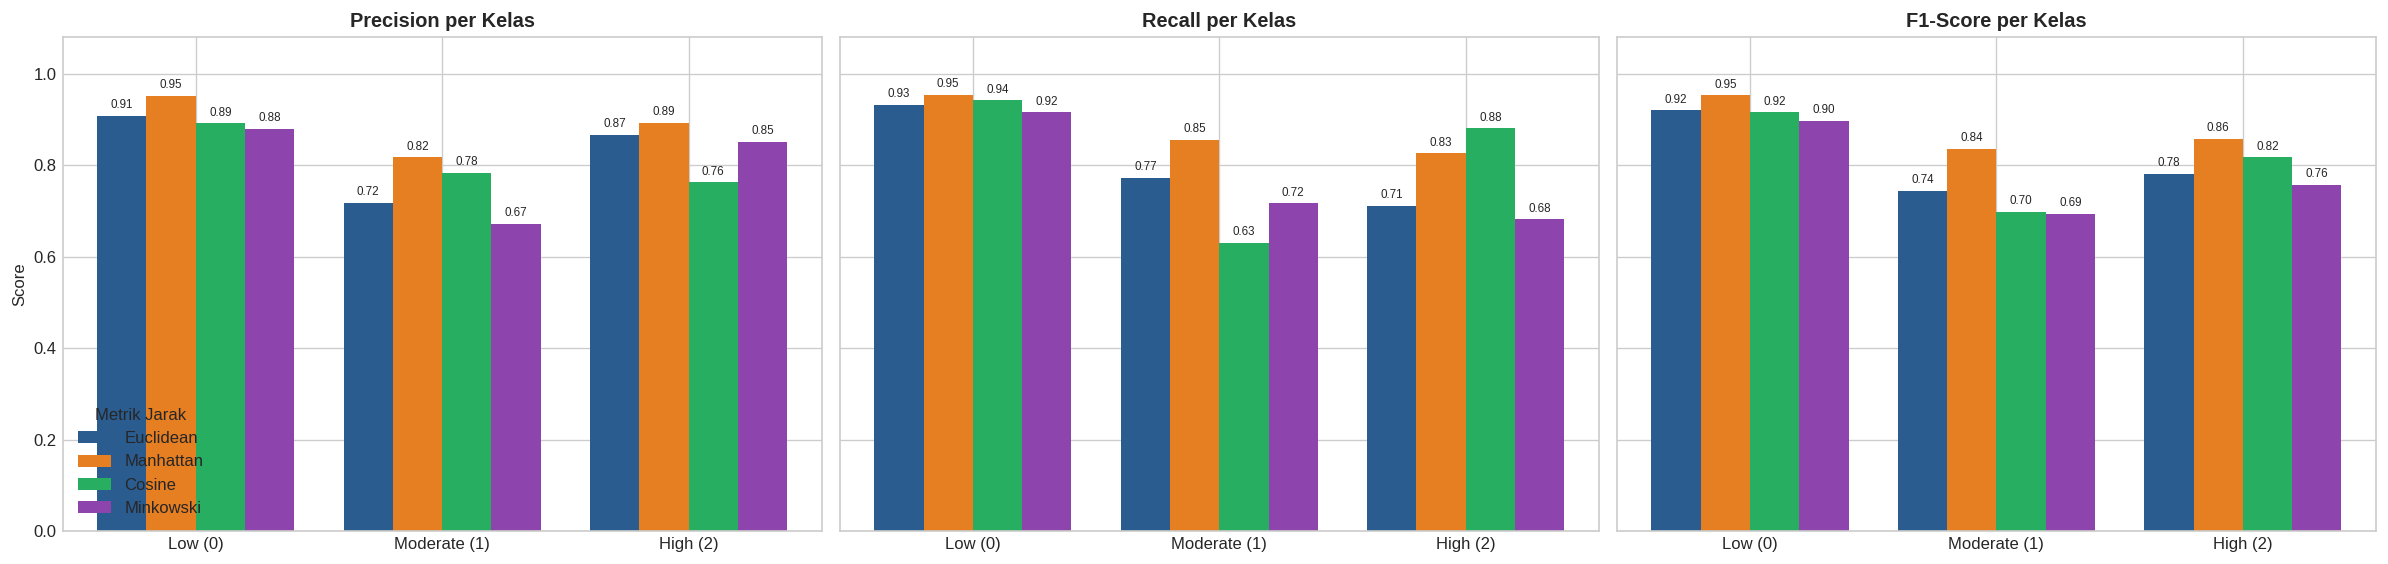

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), sharey=True)
x = np.arange(len(TARGET_NAMES))
w = 0.2

for ax, metric_name in zip(axes, ['Precision', 'Recall', 'F1-Score']):
    for i, d in enumerate(METRICS):
        vals = (
            df_per_class[df_per_class['Metrik Jarak'] == d]
            .set_index('Kelas').loc[TARGET_NAMES, metric_name].values
        )
        bars = ax.bar(x + (i - 1.5) * w, vals, w, label=d, color=COLORS[d])
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
                    f'{b.get_height():.2f}', ha='center', va='bottom', fontsize=7)
    ax.set_title(f'{metric_name} per Kelas', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(TARGET_NAMES)
    ax.set_ylim(0, 1.08)

axes[0].set_ylabel('Score')
axes[0].legend(title='Metrik Jarak')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/perbandingan_metrik_per_kelas.png', bbox_inches='tight')
plt.show()

## 4. Perbandingan Confusion Matrix

Baris = label aktual, kolom = label prediksi.

### 4.1 Confusion matrix (jumlah sampel)

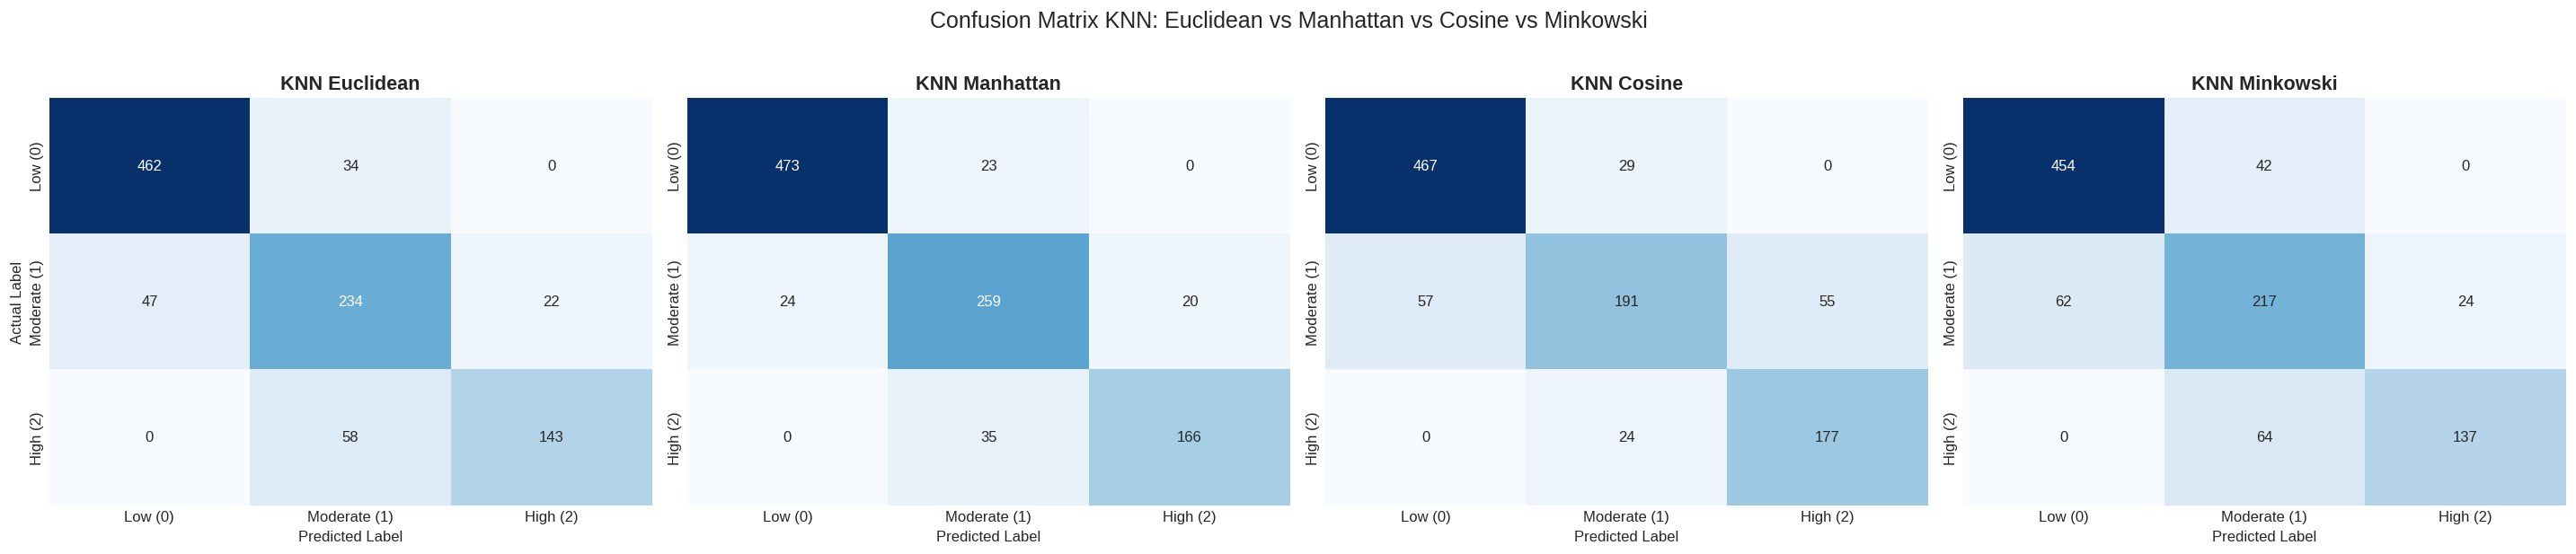

In [13]:
cms = {m: confusion_matrix(y_test, y_preds[m], labels=LABELS) for m in METRICS}

fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for i, m in enumerate(METRICS):
    sns.heatmap(
        cms[m], annot=True, fmt='d', cmap='Blues',
        xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
        ax=axes[i], cbar=False
    )
    axes[i].set_title(f'KNN {m}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.suptitle('Confusion Matrix KNN: Euclidean vs Manhattan vs Cosine vs Minkowski', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/perbandingan_confusion_matrix.png', bbox_inches='tight')
plt.show()

### 4.2 Confusion matrix ternormalisasi per baris

Nilai pada diagonal sama dengan **recall** tiap kelas, sehingga kelas dengan jumlah data berbeda bisa dibandingkan secara adil.

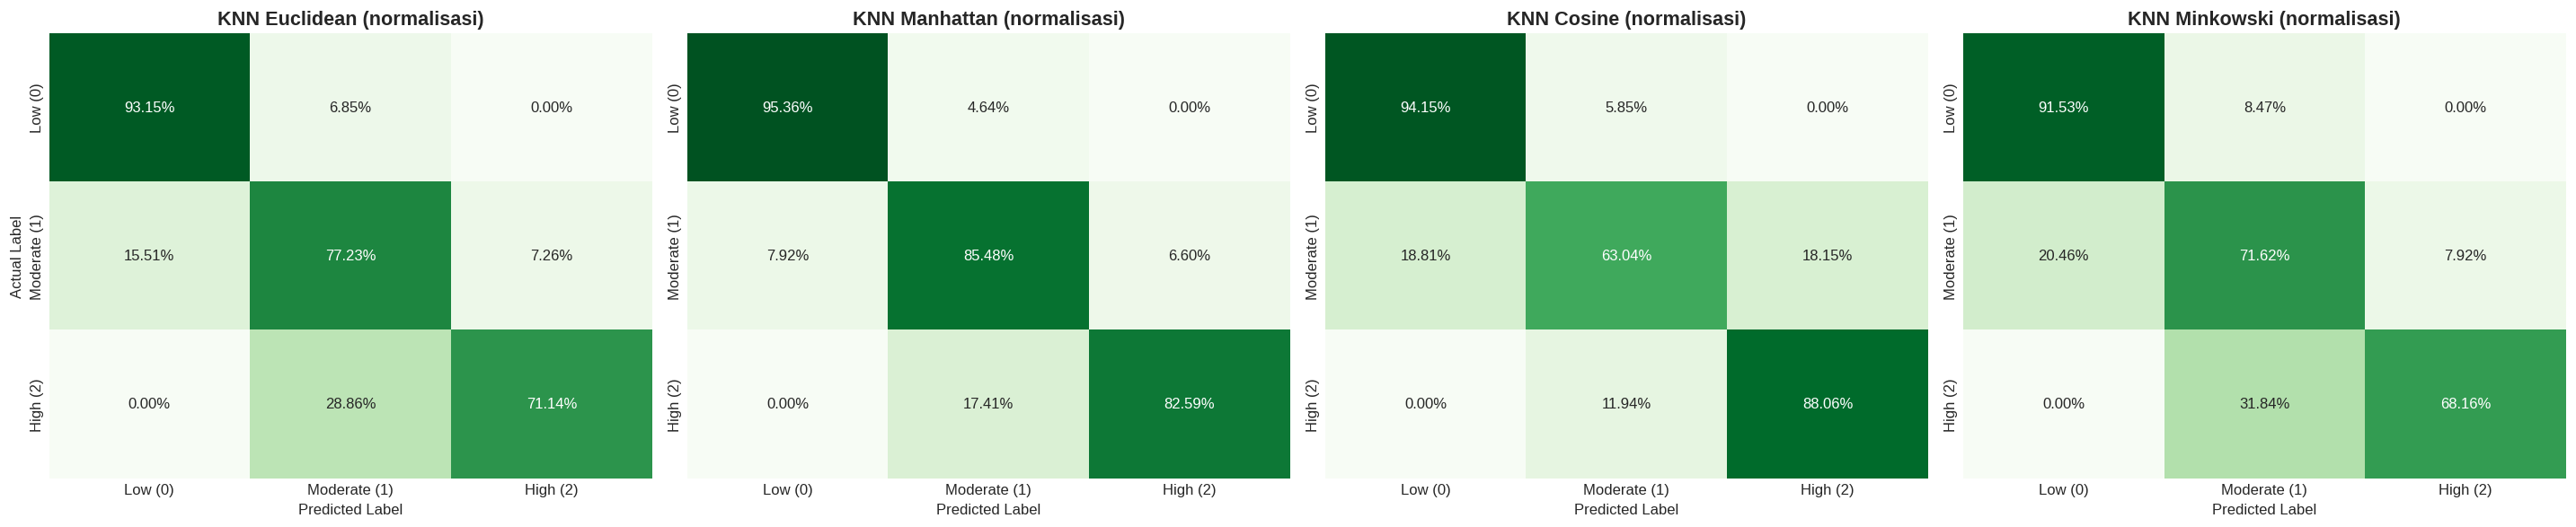

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for i, m in enumerate(METRICS):
    cm_norm = cms[m] / cms[m].sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt='.2%', cmap='Greens', vmin=0, vmax=1,
        xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
        ax=axes[i], cbar=False
    )
    axes[i].set_title(f'KNN {m} (normalisasi)', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/perbandingan_confusion_matrix_normalisasi.png', bbox_inches='tight')
plt.show()

### 4.3 Analisis jenis kesalahan

Kesalahan antara kelas yang berdekatan (Low-Moderate, Moderate-High) lebih ringan dampaknya dibanding kesalahan ekstrem Low-High.

In [15]:
err_rows = []
for m in METRICS:
    c = cms[m]
    total = c.sum()
    err_rows.append({
        'Metrik Jarak': m,
        'Total Salah Prediksi': int(total - np.trace(c)),
        'Low → Moderate': int(c[0, 1]),
        'Low → High': int(c[0, 2]),
        'Moderate → Low': int(c[1, 0]),
        'Moderate → High': int(c[1, 2]),
        'High → Low': int(c[2, 0]),
        'High → Moderate': int(c[2, 1]),
        'Kesalahan Ekstrem (Low↔High)': int(c[0, 2] + c[2, 0]),
    })

df_errors = pd.DataFrame(err_rows).set_index('Metrik Jarak')
df_errors

,Total Salah Prediksi,Low → Moderate,Low → High,Moderate → Low,Moderate → High,High → Low,High → Moderate,Kesalahan Ekstrem (Low↔High)
Metrik Jarak,,,,,,,,
Euclidean,161,34,0,47,22,0,58,0
Manhattan,102,23,0,24,20,0,35,0
Cosine,165,29,0,57,55,0,24,0
Minkowski,192,42,0,62,24,0,64,0


## 5. Stabilitas: Stratified 5-Fold Cross-Validation

Hasil pada satu pembagian data uji bisa kebetulan. Cross-validation memberi gambaran apakah selisih antar metrik jarak konsisten.
Imputasi dan standardisasi berada di dalam `Pipeline` sehingga di-fit ulang pada tiap fold.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
score_labels = {
    'accuracy': 'Accuracy',
    'precision_macro': 'Precision (Macro)',
    'recall_macro': 'Recall (Macro)',
    'f1_macro': 'F1 (Macro)'
}

cv_store = {}
cv_rows = []

for m in METRICS:
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler()),
        ('knn', make_knn(m))
    ])
    res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    cv_store[m] = res
    row = {'Metrik Jarak': m}
    for key, label in score_labels.items():
        vals = res[f'test_{key}']
        row[label] = f'{vals.mean():.4f} ± {vals.std():.4f}'
    cv_rows.append(row)

df_cv_summary = pd.DataFrame(cv_rows).set_index('Metrik Jarak')
df_cv_summary

,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
Metrik Jarak,,,,
Euclidean,0.8468 ± 0.0070,0.8419 ± 0.0088,0.8209 ± 0.0104,0.8288 ± 0.0093
Manhattan,0.8878 ± 0.0084,0.8776 ± 0.0096,0.8684 ± 0.0126,0.8721 ± 0.0111
Cosine,0.8468 ± 0.0099,0.8282 ± 0.0102,0.8304 ± 0.0138,0.8264 ± 0.0122
Minkowski,0.8096 ± 0.0085,0.8101 ± 0.0092,0.7780 ± 0.0118,0.7898 ± 0.0110


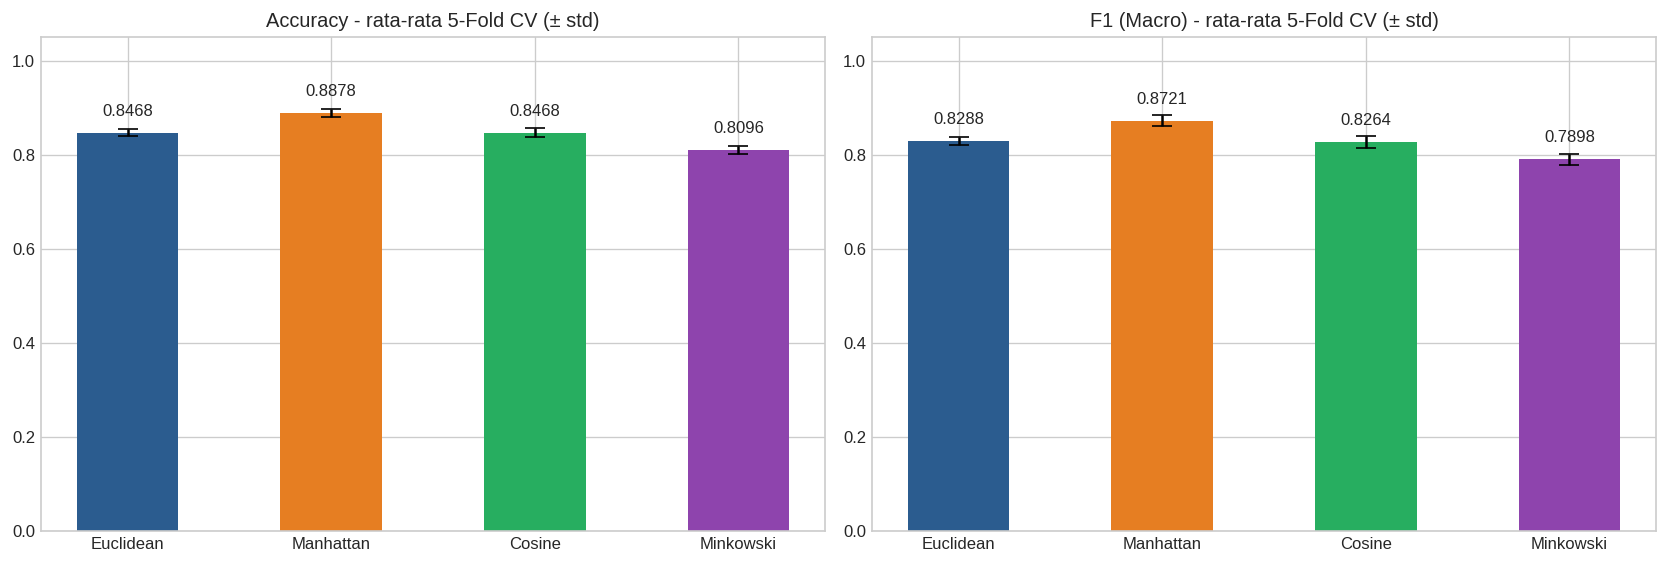

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for ax, (key, label) in zip(axes, [('accuracy', 'Accuracy'), ('f1_macro', 'F1 (Macro)')]):
    means = [cv_store[m][f'test_{key}'].mean() for m in METRICS]
    stds = [cv_store[m][f'test_{key}'].std() for m in METRICS]
    bars = ax.bar(METRICS, means, yerr=stds, capsize=6,
                  color=[COLORS[m] for m in METRICS], width=0.5)
    ax.set_title(f'{label} - rata-rata 5-Fold CV (± std)')
    ax.set_ylim(0, 1.05)
    for b, mu in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, mu + 0.03, f'{mu:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/perbandingan_cv.png', bbox_inches='tight')
plt.show()

## 6. Ringkasan dan Kesimpulan

In [18]:
df_rank = df_overall[['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1 (Macro)']].copy()
df_rank['Rata-rata CV Accuracy'] = [cv_store[m]['test_accuracy'].mean() for m in df_rank.index]
df_rank['Rata-rata CV F1 (Macro)'] = [cv_store[m]['test_f1_macro'].mean() for m in df_rank.index]
df_rank = df_rank.sort_values('F1 (Macro)', ascending=False)

display(df_rank.round(4))

best = df_rank.index[0]
worst = df_rank.index[-1]
acc_gap = (df_rank.loc[best, 'Accuracy'] - df_rank.loc[worst, 'Accuracy']) * 100
f1_gap = (df_rank.loc[best, 'F1 (Macro)'] - df_rank.loc[worst, 'F1 (Macro)']) * 100

print(f"Metrik jarak terbaik berdasarkan F1 (Macro) data uji : {best}")
print(f"  Accuracy = {df_rank.loc[best, 'Accuracy']:.4f}, "
      f"Precision (Macro) = {df_rank.loc[best, 'Precision (Macro)']:.4f}, "
      f"Recall (Macro) = {df_rank.loc[best, 'Recall (Macro)']:.4f}, "
      f"F1 (Macro) = {df_rank.loc[best, 'F1 (Macro)']:.4f}")
print(f"Selisih {best} vs {worst}: Accuracy {acc_gap:.2f} poin persen, F1 (Macro) {f1_gap:.2f} poin persen")

best_cv = df_rank['Rata-rata CV Accuracy'].idxmax()
print(f"Metrik jarak dengan rata-rata akurasi 5-Fold CV tertinggi: {best_cv}")
print('Konsisten antara data uji dan CV' if best_cv == best else 'Peringkat data uji dan CV berbeda, selisih perlu dibaca hati-hati')

# Kelas dengan F1 terendah pada model terbaik
pc = df_per_class[df_per_class['Metrik Jarak'] == best].set_index('Kelas')
weak = pc['F1-Score'].idxmin()
print(f"Kelas paling sulit diprediksi pada KNN {best}: {weak} (F1 = {pc.loc[weak, 'F1-Score']:.4f})")

extreme = df_errors['Kesalahan Ekstrem (Low↔High)']
print('Kesalahan ekstrem Low↔High per metrik:', extreme.to_dict())

,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Rata-rata CV Accuracy,Rata-rata CV F1 (Macro)
Metrik Jarak,,,,,,
Manhattan,0.898,0.8871,0.8781,0.8820,0.8878,0.8721
Euclidean,0.839,0.8307,0.8051,0.8150,0.8468,0.8288
Cosine,0.835,0.8123,0.8175,0.8105,0.8468,0.8264
Minkowski,0.808,0.8009,0.7710,0.7825,0.8096,0.7898


Metrik jarak terbaik berdasarkan F1 (Macro) data uji : Manhattan
  Accuracy = 0.8980, Precision (Macro) = 0.8871, Recall (Macro) = 0.8781, F1 (Macro) = 0.8820
Selisih Manhattan vs Minkowski: Accuracy 9.00 poin persen, F1 (Macro) 9.95 poin persen
Metrik jarak dengan rata-rata akurasi 5-Fold CV tertinggi: Manhattan
Konsisten antara data uji dan CV
Kelas paling sulit diprediksi pada KNN Manhattan: Moderate (1) (F1 = 0.8355)
Kesalahan ekstrem Low↔High per metrik: {'Euclidean': 0, 'Manhattan': 0, 'Cosine': 0, 'Minkowski': 0}


## 7. Ekspor Hasil

In [19]:
df_overall.round(4).to_csv(f'{OUTPUT_DIR}/perbandingan_metrik_keseluruhan.csv')
df_per_class.round(4).to_csv(f'{OUTPUT_DIR}/perbandingan_metrik_per_kelas.csv', index=False)
df_errors.to_csv(f'{OUTPUT_DIR}/perbandingan_jenis_kesalahan.csv')
df_cv_summary.to_csv(f'{OUTPUT_DIR}/perbandingan_cv_5fold.csv')
pd.DataFrame(runtime_rows).to_csv(f'{OUTPUT_DIR}/perbandingan_waktu_komputasi.csv', index=False)

for m in METRICS:
    pd.DataFrame(
        cms[m],
        index=[f'Aktual {n}' for n in TARGET_NAMES],
        columns=[f'Prediksi {n}' for n in TARGET_NAMES]
    ).to_csv(f'{OUTPUT_DIR}/confusion_matrix_{m.lower()}.csv')

print('Semua hasil perbandingan tersimpan di:', os.path.abspath(OUTPUT_DIR))
for name in sorted(os.listdir(OUTPUT_DIR)):
    print('-', name)

Semua hasil perbandingan tersimpan di: /content/outputPerbandinganKNN
- confusion_matrix_cosine.csv
- confusion_matrix_euclidean.csv
- confusion_matrix_manhattan.csv
- confusion_matrix_minkowski.csv
- perbandingan_confusion_matrix.png
- perbandingan_confusion_matrix_normalisasi.png
- perbandingan_cv.png
- perbandingan_cv_5fold.csv
- perbandingan_jenis_kesalahan.csv
- perbandingan_metrik_keseluruhan.csv
- perbandingan_metrik_keseluruhan.png
- perbandingan_metrik_per_kelas.csv
- perbandingan_metrik_per_kelas.png
- perbandingan_waktu_komputasi.csv
